<a href="https://colab.research.google.com/github/saran-shams/Classic_CV/blob/main/Affline_Transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Task 2



**Task # 01:**

### Lab Task: Affine Transformation Order

Apply **scaling, rotation, and translation** to the given image using a single \(3\times3\) affine transformation matrix. Perform the transformations in the following three different orders:
- **Scaling → Rotation → Translation**
- **Rotation → Scaling → Translation**, and
- **Translation → Rotation → Scaling**.

Display the three resulting images side by side and compare them.

Observe whether changing the order of the transformations changes the final output. Based on your results, explain why the order of matrix multiplication affects the final transformed image.

Observation:

1. The frame scales down and rotates cleanly. It maintains perfect 90 corners because scaling happened before rotation.
2. The frame becomes skewed into a parallelogram. Rotating first means the subsequent non-uniform scaling stretches the image along a diagonal axis, distorting the geometry.
3. • It looks identical to Order 2 because of the code typo (M2 used instead of M3). Once fixed, the parrot will swing completely out of frame (off-screen) because translating first causes it to rotate around a distant origin point.


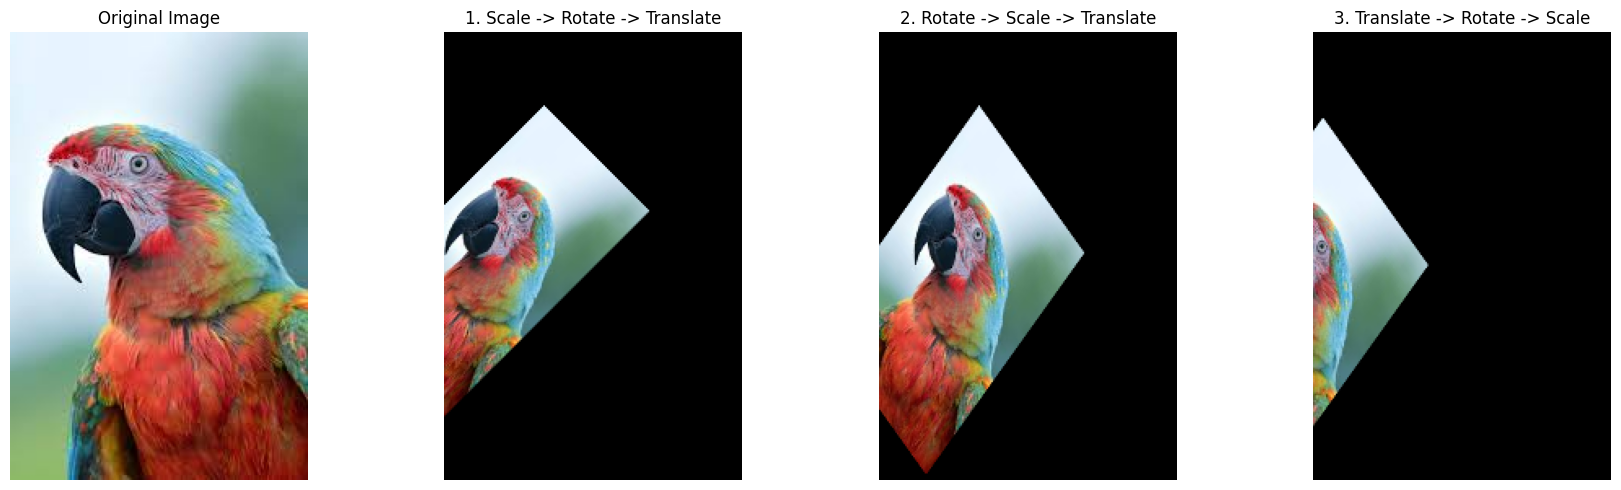

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_path = "bird.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

h, w = img.shape[:2]

scale_x, scale_y = 0.5, 0.7
angle = 45
tx, ty = w // 3, h // 6

theta = np.deg2rad(angle)

scale_matrix = np.array([[scale_x, 0, 0],
                         [0, scale_y, 0],
                         [0, 0, 1]], dtype=np.float32)

rotation_matrix = np.array([[np.cos(theta), -np.sin(theta), 0],
                            [np.sin(theta), np.cos(theta), 0],
                            [0, 0, 1]], dtype=np.float32)

translation_matrix = np.array([[1, 0, tx],
                               [0, 1, ty],
                               [0, 0, 1]], dtype=np.float32)


M1 = translation_matrix @ rotation_matrix @ scale_matrix

# 2. Rotation -> Scaling -> Translation
M2 = translation_matrix @ scale_matrix @ rotation_matrix

# 3. Translation -> Rotation -> Scaling
M3 = scale_matrix @ rotation_matrix @ translation_matrix

# cv2.warpAffine expects a 2x3 transformation matrix, so we take the top 2 rows
out1 = cv2.warpAffine(img, M1[:2, :], (w, h))
out2 = cv2.warpAffine(img, M2[:2, :], (w, h))
out3 = cv2.warpAffine(img, M3[:2, :], (w, h))

plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(out1, cv2.COLOR_BGR2RGB))
plt.title("1. Scale -> Rotate -> Translate")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(cv2.cvtColor(out2, cv2.COLOR_BGR2RGB))
plt.title("2. Rotate -> Scale -> Translate")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(out3, cv2.COLOR_BGR2RGB))
plt.title("3. Translate -> Rotate -> Scale")
plt.axis('off')

plt.tight_layout()
plt.show()


**Task # 02:**

Apply image scaling using different interpolation techniques available in OpenCV. Scale the given image up by 2× and compare the results obtained using INTER_NEAREST, INTER_LINEAR, INTER_CUBIC, and INTER_LANCZOS4. Display the original image and all scaled versions together, then compare the images by observing differences in sharpness, smoothness, pixelation, and preservation of fine details. Also print the resulting image dimensions for each interpolation method and briefly state which interpolation method produces the most visually suitable result for upscaling and why.

=== Scaled Image Dimensions ===
Original:        183 x 275
INTER_NEAREST:  366 x 550
INTER_LINEAR:   366 x 550
INTER_CUBIC:    366 x 550
INTER_LANCZOS4: 366 x 550


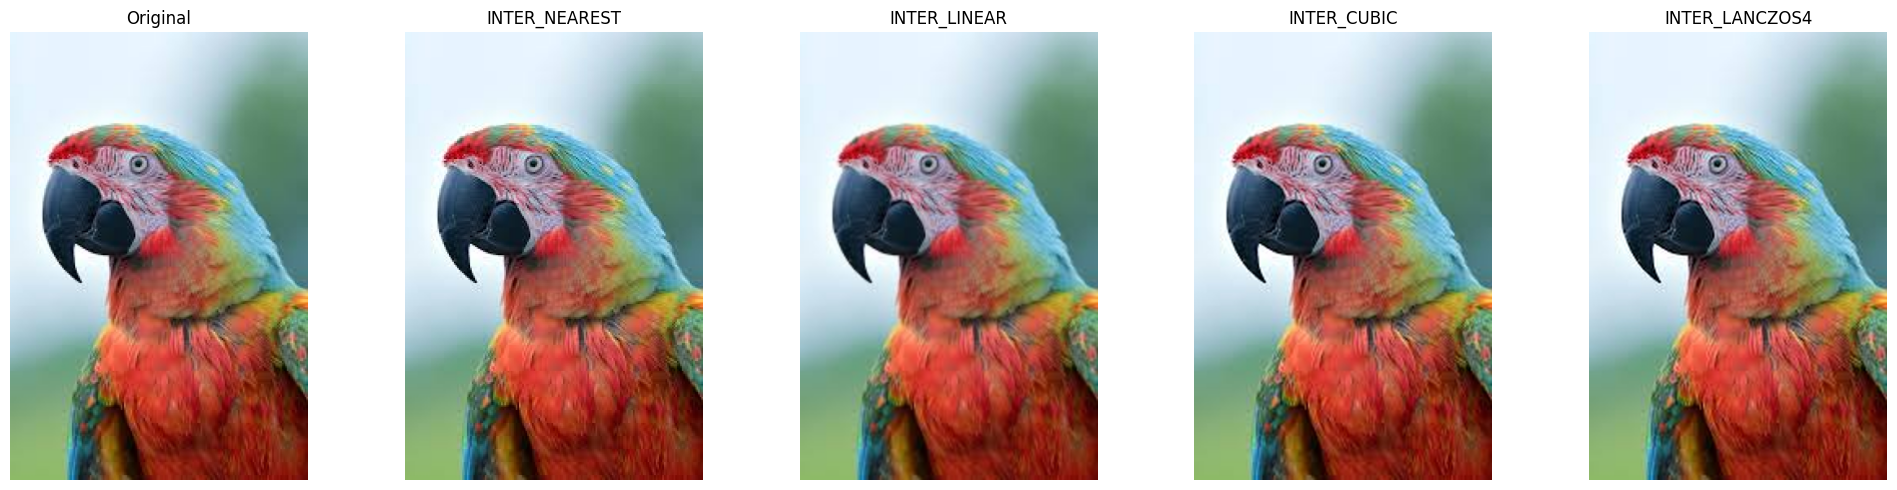

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

image_path = "bird.jpg"

img = cv2.imread(image_path)
h, w = img.shape[:2]

new_w, new_h = w * 2, h * 2

# Apply upscaling using different interpolation techniques
img_nearest  = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
img_linear   = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
img_cubic    = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_CUBIC)
img_lanczos4 = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LANCZOS4)

# Print resulting image dimensions
print("=== Scaled Image Dimensions ===")
print(f"Original:        {w} x {h}")
print(f"INTER_NEAREST:  {img_nearest.shape[1]} x {img_nearest.shape[0]}")
print(f"INTER_LINEAR:   {img_linear.shape[1]} x {img_linear.shape[0]}")
print(f"INTER_CUBIC:    {img_cubic.shape[1]} x {img_cubic.shape[0]}")
print(f"INTER_LANCZOS4: {img_lanczos4.shape[1]} x {img_lanczos4.shape[0]}")

# Display all versions side-by-side
methods = [img, img_nearest, img_linear, img_cubic, img_lanczos4]
titles = ["Original", "INTER_NEAREST", "INTER_LINEAR", "INTER_CUBIC", "INTER_LANCZOS4"]

plt.figure(figsize=(20, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.cvtColor(methods[i], cv2.COLOR_BGR2RGB))
    plt.title(titles[i], fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()


**Task # 03:**

Use any image and apply a homography transformation to change its perspective. Select four points from the image and map them to four new points to create a perspective-distorted or perspective-corrected image. Use cv2.getPerspectiveTransform() to calculate the homography matrix and cv2.warpPerspective() to apply it. Display the original and transformed images and observe how the perspective of the image changes.

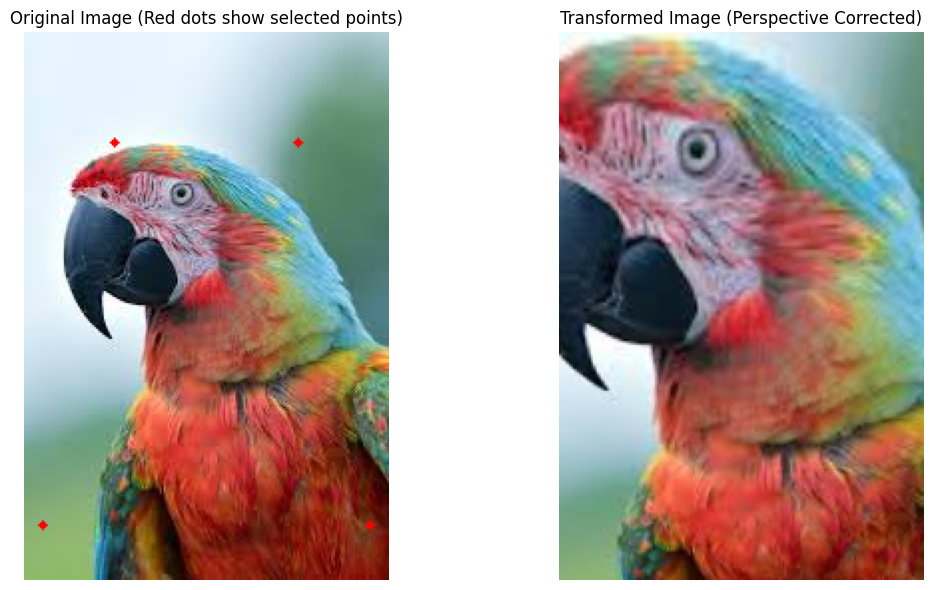

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

image_path = "bird.jpg"

img = cv2.imread(image_path)
h, w = img.shape[:2]

pts_src = np.float32([
    [int(w * 0.25), int(h * 0.20)],  # Top-left
    [int(w * 0.75), int(h * 0.20)],  # Top-right
    [int(w * 0.05), int(h * 0.90)],  # Bottom-left
    [int(w * 0.95), int(h * 0.90)]   # Bottom-right
])

pts_dst = np.float32([
    [0, 0],          # Top-left corner of output
    [w, 0],          # Top-right corner of output
    [0, h],          # Bottom-left corner of output
    [w, h]           # Bottom-right corner of output
])

H = cv2.getPerspectiveTransform(pts_src, pts_dst)

out = cv2.warpPerspective(img, H, (w, h))

img_with_points = img.copy()
for pt in pts_src:
    cv2.circle(img_with_points, (int(pt[0]), int(pt[1])), int(w * 0.015), (0, 0, 255), -1)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
# Convert BGR to RGB for correct Matplotlib rendering
plt.imshow(cv2.cvtColor(img_with_points, cv2.COLOR_BGR2RGB))
plt.title("Original Image (Red dots show selected points)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.title("Transformed Image (Perspective Corrected)")
plt.axis('off')

plt.tight_layout()
plt.show()